In [1]:
%pip install pandas numpy matplotlib seaborn scikit-learn

Note: you may need to restart the kernel to use updated packages.


Dataset loaded successfully!
Dataset shape: (7043, 21)
   customerID  gender  SeniorCitizen Partner Dependents  tenure PhoneService  \
0  7590-VHVEG  Female              0     Yes         No       1           No   
1  5575-GNVDE    Male              0      No         No      34          Yes   
2  3668-QPYBK    Male              0      No         No       2          Yes   
3  7795-CFOCW    Male              0      No         No      45           No   
4  9237-HQITU  Female              0      No         No       2          Yes   

      MultipleLines InternetService OnlineSecurity  ... DeviceProtection  \
0  No phone service             DSL             No  ...               No   
1                No             DSL            Yes  ...              Yes   
2                No             DSL            Yes  ...               No   
3  No phone service             DSL            Yes  ...              Yes   
4                No     Fiber optic             No  ...               No   

  TechS

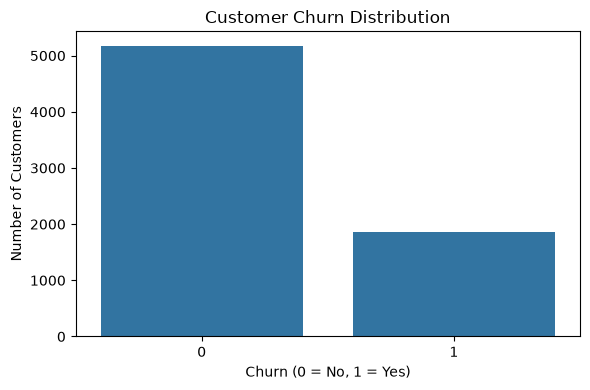

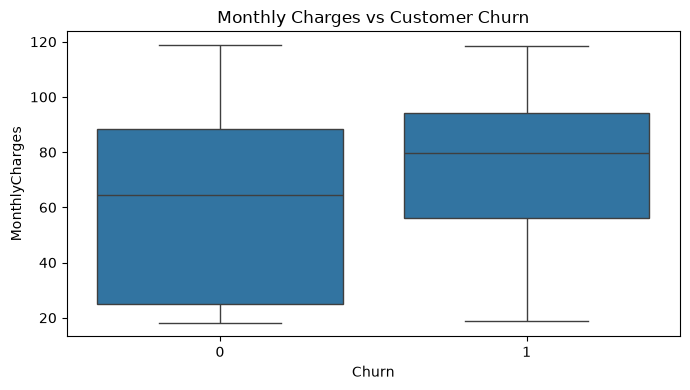

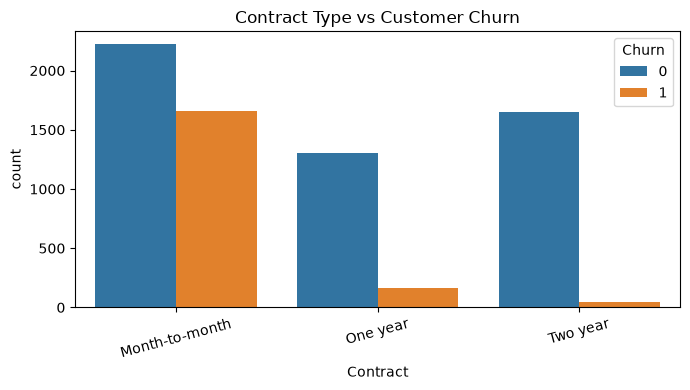


MODEL COMPARISON
              Model  Accuracy  Precision  Recall  F1 Score  ROC-AUC
Logistic Regression     0.806      0.657   0.559     0.604    0.842
      Decision Tree     0.741      0.508   0.791     0.619    0.829
      Random Forest     0.764      0.548   0.620     0.582    0.822


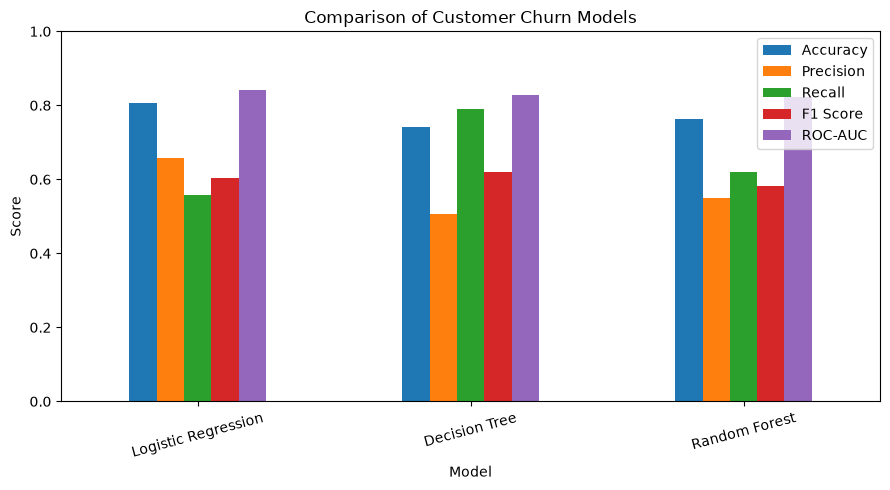


Best model based on ROC-AUC: Logistic Regression

CLASSIFICATION REPORT
              precision    recall  f1-score   support

    No Churn       0.85      0.89      0.87      1035
       Churn       0.66      0.56      0.60       374

    accuracy                           0.81      1409
   macro avg       0.75      0.73      0.74      1409
weighted avg       0.80      0.81      0.80      1409



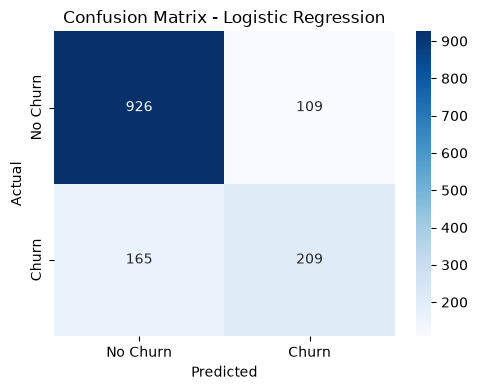

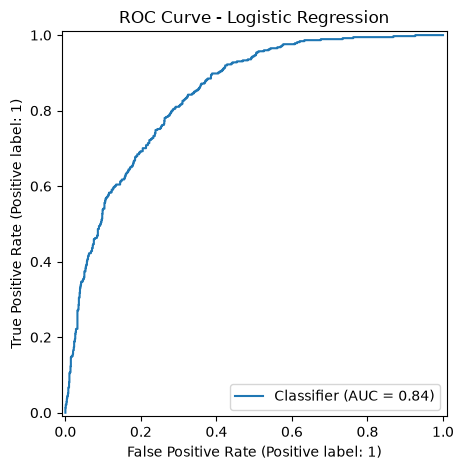

ROC-AUC Score: 0.842

TOP 15 IMPORTANT FEATURES
                                          Feature  Importance
                                  numeric__tenure    1.241319
                   categorical__Contract_Two year    0.772261
                 categorical__InternetService_DSL    0.652406
         categorical__InternetService_Fiber optic    0.640026
                          numeric__MonthlyCharges    0.596392
             categorical__Contract_Month-to-month    0.579304
                            numeric__TotalCharges    0.516708
                 categorical__PaperlessBilling_No    0.343260
categorical__DeviceProtection_No internet service    0.301082
                  categorical__InternetService_No    0.301082
  categorical__OnlineSecurity_No internet service    0.301082
     categorical__TechSupport_No internet service    0.301082
     categorical__StreamingTV_No internet service    0.301082
    categorical__OnlineBackup_No internet service    0.301082
 categorical__Streamin

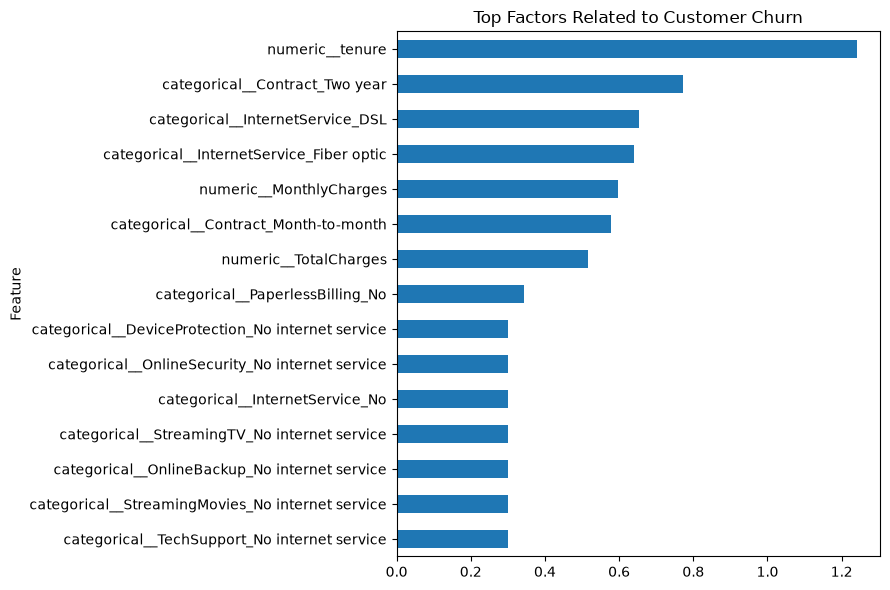


CUSTOMER CHURN RISK RESULTS
 Churn_Probability  Predicted_Churn Risk_Level                             Retention_Recommendation
          0.045294                0        Low              Continue regular service and engagement
          0.684411                1       High Contact customer and offer a suitable retention plan
          0.058721                0        Low              Continue regular service and engagement
          0.401704                0     Medium        Check customer satisfaction and offer support
          0.021548                0        Low              Continue regular service and engagement
          0.603935                1       High Contact customer and offer a suitable retention plan
          0.449225                0     Medium        Check customer satisfaction and offer support
          0.130055                0        Low              Continue regular service and engagement
          0.002881                0        Low              Continue re

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from urllib.request import urlretrieve
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report, roc_auc_score,
    RocCurveDisplay
)

# 1. Load the dataset

file_name = "Telco-Customer-Churn.csv"
url = "https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv"

try:
    if not Path(file_name).exists():
        print("Downloading customer churn dataset...")
        urlretrieve(url, file_name)
    df = pd.read_csv(file_name)
except Exception as e:
    raise RuntimeError(
        "Dataset download failed. Download the IBM Telco Customer Churn "
        "CSV file and place it in the same folder as this notebook."
    ) from e

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)
print(df.head())

# 2. Clean the data
df.columns = df.columns.str.strip()
df.drop_duplicates(inplace=True)

if "customerID" in df.columns:
    df.drop(columns=["customerID"], inplace=True)

df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
df["Churn"] = df["Churn"].astype(str).str.strip().map(
    {"Yes": 1, "No": 0}
)

df.dropna(subset=["Churn"], inplace=True)

print("\nMissing values before preprocessing:")
print(df.isnull().sum()[df.isnull().sum() > 0])

# 3. Exploratory data analysis
print("\nDataset information:")
df.info()

print("\nNumerical summary:")
print(df.describe())

plt.figure(figsize=(6, 4))
sns.countplot(data=df, x="Churn")
plt.title("Customer Churn Distribution")
plt.xlabel("Churn (0 = No, 1 = Yes)")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.show()

plt.figure(figsize=(7, 4))
sns.boxplot(data=df, x="Churn", y="MonthlyCharges")
plt.title("Monthly Charges vs Customer Churn")
plt.tight_layout()
plt.show()

plt.figure(figsize=(7, 4))
sns.countplot(data=df, x="Contract", hue="Churn")
plt.title("Contract Type vs Customer Churn")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

# 4. Prepare features and target
X = df.drop(columns=["Churn"])
y = df["Churn"].astype(int)

numeric_features = X.select_dtypes(include=["number"]).columns.tolist()
categorical_features = X.select_dtypes(
    include=["object", "str", "category", "bool"]
).columns.tolist()

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
])

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# 5. Train three classification models
models = {
    "Logistic Regression": LogisticRegression(max_iter=2000),
    "Decision Tree": DecisionTreeClassifier(
        max_depth=6, random_state=42, class_weight="balanced"
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=200, random_state=42,
        class_weight="balanced", n_jobs=-1
    )
}

results = []
trained_models = {}

for name, model in models.items():
    pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("model", model)
    ])

    pipeline.fit(X_train, y_train)

    predictions = pipeline.predict(X_test)
    probabilities = pipeline.predict_proba(X_test)[:, 1]

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(
            y_test, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_test, predictions, zero_division=0
        ),
        "F1 Score": f1_score(
            y_test, predictions, zero_division=0
        ),
        "ROC-AUC": roc_auc_score(y_test, probabilities)
    })

    trained_models[name] = pipeline

# 6. Compare model performance
results_df = pd.DataFrame(results).sort_values(
    by="ROC-AUC", ascending=False
)

print("\nMODEL COMPARISON")
print(results_df.round(3).to_string(index=False))

results_df.to_csv("model_comparison.csv", index=False)

plt.figure(figsize=(9, 5))
results_df.set_index("Model")[
    ["Accuracy", "Precision", "Recall", "F1 Score", "ROC-AUC"]
].plot(kind="bar", ax=plt.gca())
plt.title("Comparison of Customer Churn Models")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

# 7. Select the best model using ROC-AUC
best_name = results_df.iloc[0]["Model"]
best_model = trained_models[best_name]

print("\nBest model based on ROC-AUC:", best_name)

best_predictions = best_model.predict(X_test)
best_probabilities = best_model.predict_proba(X_test)[:, 1]

print("\nCLASSIFICATION REPORT")
print(classification_report(
    y_test, best_predictions,
    target_names=["No Churn", "Churn"],
    zero_division=0
))

# 8. Confusion matrix
cm = confusion_matrix(y_test, best_predictions)

plt.figure(figsize=(5, 4))
sns.heatmap(
    cm, annot=True, fmt="d", cmap="Blues",
    xticklabels=["No Churn", "Churn"],
    yticklabels=["No Churn", "Churn"]
)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix - " + best_name)
plt.tight_layout()
plt.show()

# 9. ROC curve
RocCurveDisplay.from_predictions(y_test, best_probabilities)
plt.title("ROC Curve - " + best_name)
plt.tight_layout()
plt.show()

print("ROC-AUC Score:", round(
    roc_auc_score(y_test, best_probabilities), 3
))

# 10. Feature importance
fitted_preprocessor = best_model.named_steps["preprocessor"]
fitted_classifier = best_model.named_steps["model"]

feature_names = fitted_preprocessor.get_feature_names_out()

if hasattr(fitted_classifier, "feature_importances_"):
    importance = fitted_classifier.feature_importances_
elif hasattr(fitted_classifier, "coef_"):
    importance = np.abs(fitted_classifier.coef_[0])
else:
    importance = None

if importance is not None:
    feature_importance = pd.DataFrame({
        "Feature": feature_names,
        "Importance": importance
    }).sort_values("Importance", ascending=False)

    print("\nTOP 15 IMPORTANT FEATURES")
    print(feature_importance.head(15).to_string(index=False))

    feature_importance.head(15).sort_values(
        "Importance"
    ).plot(
        x="Feature", y="Importance", kind="barh",
        figsize=(9, 6), legend=False
    )
    plt.title("Top Factors Related to Customer Churn")
    plt.tight_layout()
    plt.show()

    feature_importance.to_csv("feature_importance.csv", index=False)

# 11. Predict churn risk for customers
customer_results = X_test.copy()
customer_results["Actual_Churn"] = y_test
customer_results["Churn_Probability"] = best_probabilities
customer_results["Predicted_Churn"] = best_predictions

customer_results["Risk_Level"] = pd.cut(
    customer_results["Churn_Probability"],
    bins=[-0.001, 0.30, 0.60, 1.001],
    labels=["Low", "Medium", "High"]
)

# 12. Suggest retention actions
def retention_action(row):
    if row["Risk_Level"] == "High":
        return "Contact customer and offer a suitable retention plan"
    elif row["Risk_Level"] == "Medium":
        return "Check customer satisfaction and offer support"
    return "Continue regular service and engagement"

customer_results["Retention_Recommendation"] = customer_results.apply(
    retention_action, axis=1
)

print("\nCUSTOMER CHURN RISK RESULTS")
print(customer_results[
    ["Churn_Probability", "Predicted_Churn",
     "Risk_Level", "Retention_Recommendation"]
].head(10).to_string(index=False))

customer_results.to_csv("customer_churn_predictions.csv", index=False)

# 13. Summarize churn risk
print("\nCUSTOMER RISK SUMMARY")
print(customer_results["Risk_Level"].value_counts())

print("\nRetention recommendations:")
print(customer_results["Retention_Recommendation"].value_counts())

# 14. Save cleaned dataset and final report metrics
df.to_csv("cleaned_churn_dataset.csv", index=False)

with open("project_summary.txt", "w", encoding="utf-8") as f:
    f.write("CUSTOMER CHURN PREDICTION AND RETENTION ANALYSIS\n")
    f.write(f"Dataset rows: {len(df)}\n")
    f.write(f"Best model: {best_name}\n")
    f.write("\nModel comparison:\n")
    f.write(results_df.round(3).to_string(index=False))
    f.write("\n\nThis model estimates churn risk and supports "
            "customer retention planning.\n")

print("\nProject completed successfully!")
print("Files saved:")
print("1. cleaned_churn_dataset.csv")
print("2. model_comparison.csv")
print("3. feature_importance.csv")
print("4. customer_churn_predictions.csv")
print("5. project_summary.txt")